# **Google Trends and Financial Markets: Exploratory Data Analysis**

**Contributor:** Atharva Amberkar  
**Alternative-data category:** Google Trends search interest  
**Purpose:** Examine whether search interest for “FII Buying” contains useful information alongside NIFTY 50 market data.


# **1. Loading the Price data from yfinance**

In [1]:
%pip install -q "urllib3<2" numpy pandas matplotlib yfinance scikit-learn pytrends requests

In [2]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")

KEYWORD = "FII Buying"
GEO = "IN"
TICKER = "^NSEI"
START_DATE = "2022-01-01"
END_DATE = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

print("Keyword:", KEYWORD)
print("Region:", GEO if GEO else "Worldwide")
print("Ticker:", TICKER)
print("Date range:", START_DATE, "to", END_DATE)

Keyword: FII Buying
Region: IN
Ticker: ^NSEI
Date range: 2022-01-01 to 2026-10-19


In [3]:
market_data = yf.download(
    TICKER,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)

market = yf.download(TICKER, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)
market = market.reset_index()
market.columns = market.columns.get_level_values(0)
market = market.rename(columns={"Date": "date", "Close": "close"})
market["close"] = pd.to_numeric(market["close"], errors="coerce")
market = market[["date", "close"]].dropna().sort_values("date").reset_index(drop=True)
market["return_pct"] = market["close"].pct_change() * 100


print("Priting Market data fetched")
display(market)
print("Printing the stats of market Data")
display(market["close"].describe())

Priting Market data fetched


Price,date,close,return_pct
0,2022-01-03,17625.699219,NaN
1,2022-01-04,17805.250000,1.018687
2,2022-01-05,17925.250000,0.673959
3,2022-01-06,17745.900391,-1.000542
4,2022-01-07,17812.699219,0.376418
...,...,...,...
1178,2026-10-12,22363.349609,-0.697586
1179,2026-10-13,22721.949219,1.603515
1180,2026-10-14,22622.699219,-0.436802
1181,2026-10-15,22997.349609,1.656082


Printing the stats of market Data


,close
count,1183.000000
mean,21567.430410
std,3210.683796
min,15293.500000
25%,18186.375000
50%,22508.750000
75%,24389.724609
max,26328.550781


# **2. Loading the Trends data from Google Trends**

In [4]:
from pytrends.request import TrendReq

pytrends = TrendReq(hl="en-US", tz=0)
trends_end_date = (pd.Timestamp(END_DATE) - pd.Timedelta(days=1)).strftime("%Y-%m-%d")
timeframe = START_DATE + " " + trends_end_date

pytrends.build_payload(
    [KEYWORD],
    timeframe=timeframe,
    geo=GEO
)

trends = pytrends.interest_over_time().reset_index()
trends

,date,FII Buying,isPartial
0,2021-12-26,16,False
1,2022-01-02,37,False
2,2022-01-09,27,False
3,2022-01-16,30,False
4,2022-01-23,32,False
...,...,...,...
247,2026-09-20,22,False
248,2026-09-27,25,False
249,2026-10-04,26,False
250,2026-10-11,24,False


In [5]:
trends = trends.drop(columns=["isPartial"], errors="ignore")
trends = trends.rename(columns={KEYWORD: "interest", "date": "date"})
trends["date"] = pd.to_datetime(trends["date"], errors="coerce")
trends["interest"] = pd.to_numeric(trends["interest"], errors="coerce")
trends = trends[["date", "interest"]].dropna(subset=["date"])
trends = trends.sort_values("date").drop_duplicates(subset="date").reset_index(drop=True)
trends["date"] = pd.to_datetime(trends["date"], errors="coerce", utc=True).dt.tz_convert(None)
trends["interest"] = pd.to_numeric(trends["interest"], errors="coerce")

print("Number of Google Trends rows:", len(trends))
print("invalid_dates", trends["date"].isna().sum())
print("duplicate_dates", trends["date"].duplicated().sum())
print("missing_interest", trends["interest"].isna().sum())
print( "duplicate dates", trends["date"].duplicated().sum())
trends

Number of Google Trends rows: 252
invalid_dates 0
duplicate_dates 0
missing_interest 0
duplicate dates 0


,date,interest
0,2021-12-26,16
1,2022-01-02,37
2,2022-01-09,27
3,2022-01-16,30
4,2022-01-23,32
...,...,...
247,2026-09-20,22
248,2026-09-27,25
249,2026-10-04,26
250,2026-10-11,24


# **3. Align the two datasets**

In [6]:
trends["date"] = pd.to_datetime(trends["date"], errors="coerce").dt.normalize()
market["date"] = pd.to_datetime(market["date"], errors="coerce").dt.normalize()

merged = pd.merge_asof(market.sort_values("date"),trends.sort_values("date"),on="date",direction="backward")
merged = merged.sort_values("date").reset_index(drop=True)
merged["return_pct"] = merged["close"].pct_change() * 100
merged["interest_change"] = merged["interest"].diff()

print("Number of aligned daily rows:", len(merged))
print("Aligned data starts:", merged["date"].min())
print("Aligned data ends:", merged["date"].max())
print("duplicate_dates", merged["date"].duplicated().sum())
print("null values",merged["close"].isna().sum())


Number of aligned daily rows: 1183
Aligned data starts: 2022-01-03 00:00:00
Aligned data ends: 2026-10-16 00:00:00
duplicate_dates 0
null values 0


# **4. Analysis**

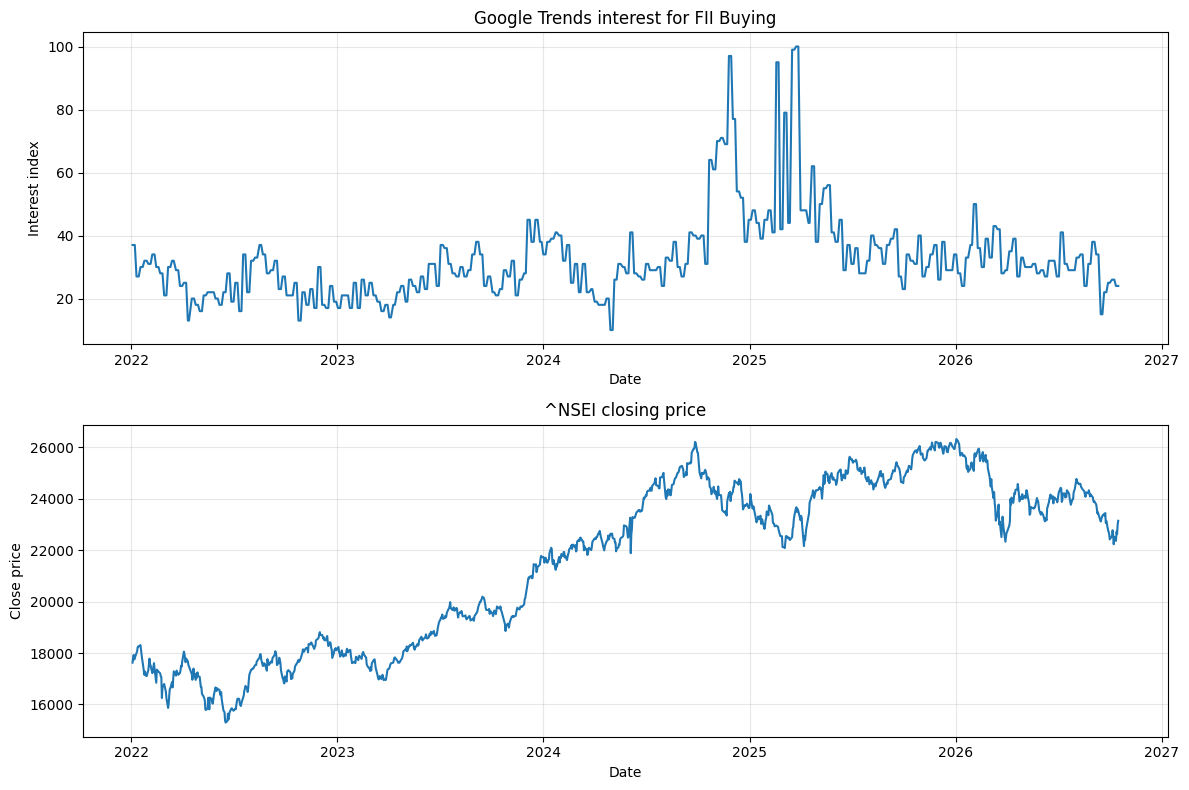

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(merged["date"], merged["interest"])
axes[0].set_title("Google Trends interest for " + KEYWORD)
axes[0].set_ylabel("Interest index")
axes[0].set_xlabel("Date")
axes[0].grid(True, alpha=0.3)


axes[1].plot(merged["date"], merged["close"])
axes[1].set_title(TICKER + " closing price")
axes[1].set_ylabel("Close price")
axes[1].set_xlabel("Date")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
close,1183.0,21567.430410,3210.683796,15293.50000,18186.375000,22508.750000,24389.724609,26328.550781
return_pct,1182.0,0.026819,0.867271,-5.92936,-0.423101,0.034281,0.524790,3.818307
interest,1183.0,32.624683,13.809967,10.00000,24.000000,30.000000,37.000000,100.000000
interest_change,1182.0,-0.010998,4.893174,-53.00000,0.000000,0.000000,0.000000,55.000000


,interest,close,return_pct,interest_change
interest,1.000000,0.424606,0.039296,0.177440
close,0.424606,1.000000,0.016564,-0.003054
return_pct,0.039296,0.016564,1.000000,0.052303
interest_change,0.177440,-0.003054,0.052303,1.000000


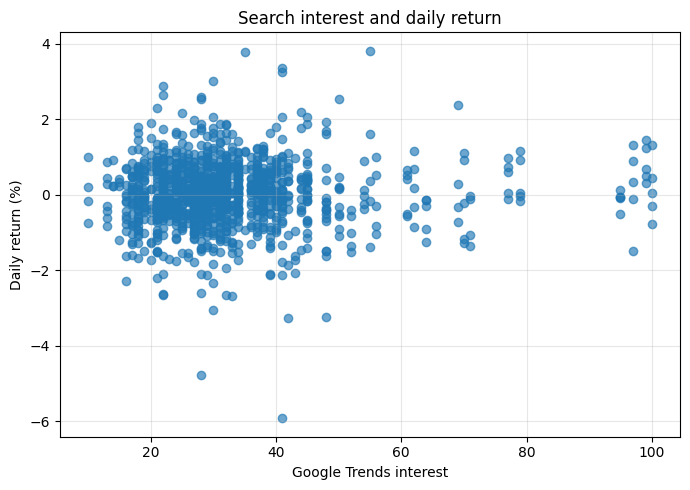

In [8]:
columns = ["close", "return_pct", "interest", "interest_change"]
display(merged[columns].describe().T)
display(merged[["interest", "close", "return_pct", "interest_change"]].corr())

plt.figure(figsize=(7, 5))
plt.scatter(merged["interest"], merged["return_pct"], alpha=0.65)
plt.title("Search interest and daily return")
plt.xlabel("Google Trends interest")
plt.ylabel("Daily return (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


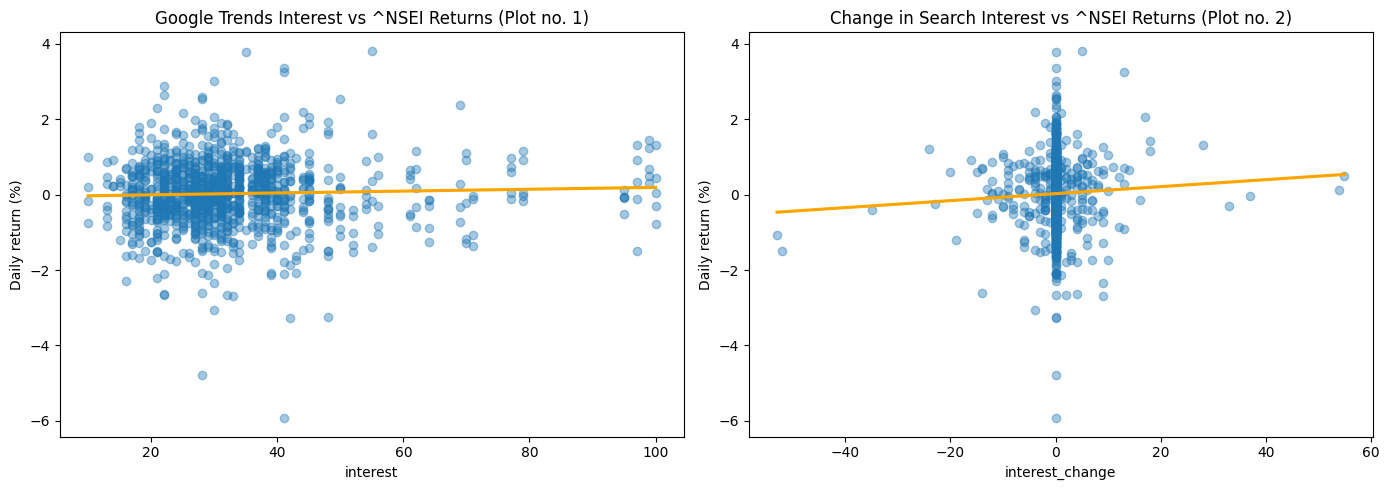

In [9]:
fig, axes = plt.subplots(1,2, figsize=(14, 5))

#Interest plot against Return percentage
sns.regplot(
    data=merged,
    x="interest",
    y="return_pct",
    ax=axes[0],
    ci=None,
    line_kws={"color": "orange"},
    scatter_kws={"alpha": 0.4}
)
axes[0].set_title("Google Trends Interest vs " + TICKER +  " Returns (Plot no. 1)" )
axes[0].set_ylabel("Daily return (%)")

#Interest change plot against Return percentage
sns.regplot(
    data=merged,
    x="interest_change",
    y="return_pct",
    ax=axes[1],
    ci=None,
    line_kws={"color": "orange"},
    scatter_kws={"alpha": 0.4}
)
axes[1].set_title("Change in Search Interest vs " + TICKER +  " Returns (Plot no. 2)")
axes[1].set_ylabel("Daily return (%)")

plt.tight_layout()
plt.show()


In [10]:
pairs = [
    ("interest", "return_pct"),
    ("interest_change", "return_pct")
]

corr_rows = []

for x, y in pairs:
    data = merged[[x, y]].dropna()
    n = len(data)

    if n > 1 and data[x].nunique() > 1 and data[y].nunique() > 1:
        pearson_corr, pearson_p = pearsonr(data[x], data[y])
        spearman_corr, spearman_p = spearmanr(data[x], data[y])
    else:
        pearson_corr, pearson_p = np.nan, np.nan
        spearman_corr, spearman_p = np.nan, np.nan

    corr_rows.append({
        "Variables": f"{x} vs {y}",
        "Sample size": n,
        "Pearson correlation": pearson_corr,
        "Pearson p-value": pearson_p,
        "Spearman correlation": spearman_corr,
        "Spearman p-value": spearman_p
    })

corr_table = pd.DataFrame(corr_rows)
display(corr_table)

,Variables,Sample size,Pearson correlation,Pearson p-value,Spearman correlation,Spearman p-value
0,interest vs return_pct,1182,0.039296,0.176988,0.045083,0.121359
1,interest_change vs return_pct,1182,0.052303,0.072254,0.009000,0.757251


# **5. 80/20 Test Split**

In [12]:
test_data = merged[["date", "return_pct", "interest", "interest_change"]].copy()
test_data = test_data.sort_values("date").reset_index(drop=True)

test_data["interest_lag"] = test_data["interest"].shift(1)
test_data["change_lag"] = test_data["interest_change"].shift(1)
test_data = test_data.replace([np.inf, -np.inf], np.nan).dropna(
    subset=["return_pct", "interest_lag", "change_lag"]
).reset_index(drop=True)

if len(test_data) < 10:
    print("There are not enough observations for the holdout test.")
else:
    split = int(len(test_data) * 0.8)
    train = test_data.iloc[:split]
    test = test_data.iloc[split:]

    features = ["interest_lag", "change_lag"]
    X_train = train[features]
    y_train = train["return_pct"]
    X_test = test[features]
    y_test = test["return_pct"]

    model = LinearRegression()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    baseline = np.full(len(test), y_train.mean())

    comparison = pd.DataFrame({
        "Model": ["Linear regression", "Mean-return baseline"],
        "Test observations": [len(test), len(test)],
        "MAE": [
            mean_absolute_error(y_test, predictions),
            mean_absolute_error(y_test, baseline)
        ],
        "RMSE": [
            np.sqrt(mean_squared_error(y_test, predictions)),
            np.sqrt(mean_squared_error(y_test, baseline))
        ],
        "R-squared": [
            r2_score(y_test, predictions),
            r2_score(y_test, baseline)
        ]
    })

    print("Training observations:", len(train))
    print("Test observations:", len(test))
    print("Test period:", test["date"].min(), "to", test["date"].max())
    display(comparison)

Training observations: 944
Test observations: 237
Test period: 2025-10-31 00:00:00 to 2026-10-16 00:00:00


,Model,Test observations,MAE,RMSE,R-squared
0,Linear regression,237,0.653007,0.878468,-0.01057
1,Mean-return baseline,237,0.653167,0.878142,-0.00982


# **6. Interpretation**

# Scatter Plot no. 1
The regression line is almost flat with a slight upward slope and most observations are cclustered around the area of 20 to 40. The scatter plot suggests even though the correlation is positive it is too weak to generate any meaning full conclusion around the keyword "FII Buying" and Daily Returns of NIFTY 50 Index.

# Scatter Plot no. 2
However the second plot tells us a different story. The Regression Line in the second plot slopes noticeably upwards compared to the first plot. Most of the Scatter plots are around 0. Meaning the Correlation is positive but not enough to conclude that the keyword "FII Buying" and Daily Returns of NIFTY 50 Index useful to forecast Future Returns of NIfty 50 Index.

# Correlation Table

Even the correlation table shows a very weak positive relationship between Google Trends search interest and NIFTY 50 returns. Both Pearson and Spearman correlations are close to zero, and their p-values are above 0.05. The change in search interest has a higher Pearson correlation, but it is still very weak.

# 80/20 Test Split
In the 80/20 test split the linear regression model performs almost the same as the mean-return baseline. It has a slightly lower MAE but a higher RMSE and a worse R-squared value. Both models have negative R-squared values thus proving no predictive power.
